# 04 · Segmentos de clientes, casos raros y red neuronal (Producto 2)
**Parte A:** ¿qué tipos de clientes hay, sin usar la respuesta?
**Parte B:** ¿qué tienen de especial los casos raros?
**Parte C:** ¿una red neuronal mejora a nuestro mejor modelo?

In [1]:
!pip install -q optuna lightgbm

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222, archivo bank-additional-full.csv), copia pública en GitHub.
# Plan B: descarguen bank-additional-full.csv desde UCI y súbanlo al panel Archivos de Colab.
URL = "https://raw.githubusercontent.com/selva86/datasets/master/bank-full.csv"

NOMBRES = {
    "age": "edad", "job": "ocupacion", "marital": "estado_civil", "education": "educacion",
    "default": "en_mora", "housing": "hipoteca", "loan": "prestamo", "contact": "tipo_contacto",
    "month": "mes", "day_of_week": "dia_semana", "duration": "duracion_llamada",
    "campaign": "contactos_campana", "pdays": "dias_ultimo_contacto", "previous": "contactos_previos",
    "poutcome": "resultado_previo", "emp.var.rate": "tasa_var_empleo", "cons.price.idx": "ipc",
    "cons.conf.idx": "confianza_consumidor", "euribor3m": "euribor3m", "nr.employed": "num_empleados"}

NUMERICAS = ["edad", "contactos_campana", "dias_ultimo_contacto", "contactos_previos",
             "tasa_var_empleo", "ipc", "confianza_consumidor", "euribor3m", "num_empleados"]
CATEGORICAS = ["ocupacion", "estado_civil", "educacion", "en_mora", "hipoteca", "prestamo",
               "tipo_contacto", "mes", "dia_semana", "resultado_previo"]
# duracion_llamada NO entra al modelo: solo se conoce DESPUÉS de la llamada (fuga de datos).

def cargar_datos():
    try:
        df = pd.read_csv(URL, sep=";")
    except Exception:
        df = pd.read_csv("bank-additional-full.csv", sep=";")
    df = df.rename(columns=NOMBRES)
    # 999 significa "nunca fue contactado": no es una cantidad, lo convertimos en faltante
    df["dias_ultimo_contacto"] = df["dias_ultimo_contacto"].replace(999, np.nan)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df.drop(columns="y")

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(41188, 21) | suscriben: 11.3%


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: el test se usa una sola vez, al final
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesador():
    # add_indicator=True crea la columna "nunca fue contactado" a partir de los 999
    num = Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                    ("escalar", StandardScaler())])
    # "unknown" se mantiene como categoría propia: no saber si tiene mora también informa
    cat = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

## Parte A · Segmentos con k-means

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df["contactado_antes"] = df["dias_ultimo_contacto"].notna().astype(int)
VARS_SEG = ["edad", "contactos_campana", "contactos_previos", "contactado_antes",
            "euribor3m", "num_empleados", "tasa_var_empleo"]
Z = StandardScaler().fit_transform(df[VARS_SEG])
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    print(f"k = {k}: silueta = {silhouette_score(Z, km.labels_, sample_size=3000, random_state=42):.3f}")

k = 2: silueta = 0.514
k = 3: silueta = 0.538


k = 4: silueta = 0.525
k = 5: silueta = 0.389


k = 6: silueta = 0.385


k = 3 y k = 4 tienen silueta parecida. Elegimos **k = 4** porque separa un grupo adicional con utilidad práctica (los clientes saturados de llamadas).

In [5]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
df["segmento"] = km.labels_
perfiles = df.groupby("segmento")[VARS_SEG].mean().round(2)
perfiles["clientes"] = df["segmento"].value_counts().sort_index()
perfiles["% suscribe"] = (df.groupby("segmento")["suscribe"].mean() * 100).round(1)   # recién aquí miramos y
perfiles.sort_values("% suscribe")

,edad,contactos_campana,contactos_previos,contactado_antes,euribor3m,num_empleados,tasa_var_empleo,clientes,% suscribe
segmento,,,,,,,,,
2,40.53,11.48,0.01,0.00,4.84,5217.56,1.24,2084,3.9
0,40.17,2.11,0.03,0.00,4.81,5212.89,1.10,25609,4.9
1,39.39,2.09,0.32,0.00,1.20,5077.76,-2.03,11965,19.5
3,41.88,1.83,1.69,0.99,0.98,5028.82,-2.09,1530,63.4


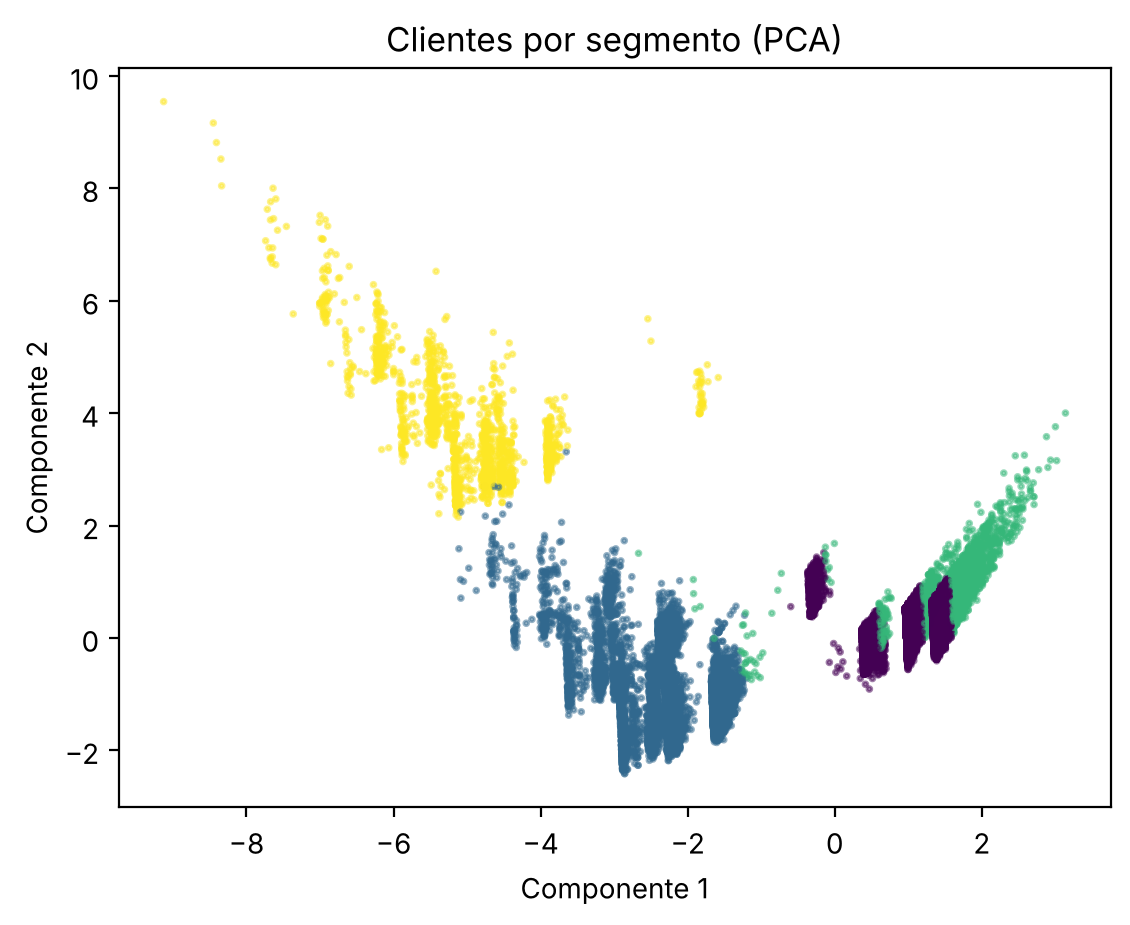

In [6]:
from sklearn.decomposition import PCA
mapa = PCA(n_components=2, random_state=42).fit_transform(Z)
plt.scatter(mapa[:, 0], mapa[:, 1], c=df["segmento"], s=3, cmap="viridis", alpha=0.5)
plt.xlabel("Componente 1"); plt.ylabel("Componente 2"); plt.title("Clientes por segmento (PCA)"); plt.show()

**Lectura de los segmentos** (sin usar la respuesta para formarlos):

| Segmento | Clientes | Rasgos | % suscribe |
|---|---|---|---|
| Saturados | 2 084 | ~11 llamadas en esta campaña, contexto de euribor alto | 3,9 % |
| Fríos en época de tasas altas | 25 609 | Nunca contactados antes, euribor ~4,8 % | 4,9 % |
| Fríos en época de tasas bajas | 11 965 | Nunca contactados antes, euribor ~1,2 % | 19,5 % |
| **Recontactados** | **1 530** | Ya contactados en una campaña anterior, euribor bajo | **63,4 %** |

**Uso práctico:** (1) priorizar siempre a los recontactados; (2) **dejar de llamar** a los saturados: la 11.ª llamada casi nunca funciona y molesta al cliente; (3) el contexto de tasas define cuándo conviene lanzar una campaña.

## Parte B · Casos raros con Isolation Forest

In [7]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.03, random_state=42).fit(Z)
df["raro"] = iso.predict(Z) == -1
print(f"Clientes raros: {df['raro'].sum()}")
print(df.groupby("raro")["suscribe"].mean().rename({False: "resto", True: "raros"}).map("{:.1%}".format))
comp = df.groupby("raro")[VARS_SEG].mean().T.round(2); comp.columns = ["resto", "raros"]
comp

Clientes raros: 1236
raro
resto     9.8%
raros    58.7%
Name: suscribe, dtype: str


,resto,raros
edad,39.84,46.07
contactos_campana,2.56,2.75
contactos_previos,0.12,1.89
contactado_antes,0.01,0.81
euribor3m,3.70,1.03
num_empleados,5171.75,5014.57
tasa_var_empleo,0.15,-1.97


**¿Qué hace "raro" a un cliente?** Haber sido contactado en campañas anteriores (81 % de los raros vs. 1 % del resto) en un periodo de tasas bajas. Los raros suscriben en un **59 %** contra 10 % del resto: aquí lo "raro" no es un error de datos, es una **oportunidad**.

## Parte C · Red neuronal (MLP) contra Random Forest y LightGBM

In [8]:
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

candidatos = {
    "Red neuronal (MLP 32-16)": MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True,
                                              max_iter=500, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=16, random_state=42, verbose=-1),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}
for nombre, m in candidatos.items():
    r = cross_validate(Pipeline([("prep", preprocesador()), ("modelo", m)]), X_tr, y_tr, cv=cv,
                       scoring={"pr": "average_precision", "roc": "roc_auc"})
    print(f"{nombre:<26} PR-AUC = {r['test_pr'].mean():.3f} ± {r['test_pr'].std():.3f} · "
          f"ROC-AUC = {r['test_roc'].mean():.3f} ± {r['test_roc'].std():.3f}")

Red neuronal (MLP 32-16)   PR-AUC = 0.444 ± 0.010 · ROC-AUC = 0.787 ± 0.004


LightGBM                   PR-AUC = 0.468 ± 0.012 · ROC-AUC = 0.798 ± 0.003


Random Forest              PR-AUC = 0.464 ± 0.010 · ROC-AUC = 0.790 ± 0.004


**Conclusión:** la red neuronal (PR-AUC 0,444) no supera a LightGBM (0,468) ni a Random Forest (0,464). En datos de tabla con muchas variables categóricas, los ensambles de árboles siguen siendo la mejor opción; la red agrega complejidad sin ganancia.